# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

A 29-year-old physical therapist lives alone in a rented one-bedroom apartment in Boston and is the household's only earner. He drives a used car he is still paying off to an outpatient clinic in Waltham, a commute the T does not serve well. Most of his budget goes to rent, then groceries, the car payment and gas, eating out, utilities, and phone and internet.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [35]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent",               "Price_2019": 2250, "Price_2024": 2700, "weight": 0.47},
    {"Item": "Groceries",          "Price_2019": 380,  "Price_2024": 470,  "weight": 0.15},
    {"Item": "Dining out",         "Price_2019": 180,  "Price_2024": 235,  "weight": 0.10},
    {"Item": "Utilities",          "Price_2019": 140,  "Price_2024": 185,  "weight": 0.07},
    {"Item": "Phone and internet", "Price_2019": 115,  "Price_2024": 125,  "weight": 0.04},
    {"Item": "Gasoline",           "Price_2019": 115,  "Price_2024": 150,  "weight": 0.05},
    {"Item": "Used car payment",   "Price_2019": 350,  "Price_2024": 480,  "weight": 0.12},
]

In [36]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [37]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    total = 0
    for item in basket:
        total = total + item["weight"] * item[current_key] / item[base_key]
    return total * 100

def price_change(old, new):
    """Percentage change from old to new."""
    return (new - old) / old * 100

In [38]:
# 1. the unweighted average price change across categories
changes = []
for item in household_basket:
    change = price_change(item["Price_2019"], item["Price_2024"])
    changes.append(change)
    print(item["Item"], round(change, 1), "%")
unweighted = sum(changes) / len(changes)
print("Unweighted average change:", round(unweighted, 1), "%")

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
household_index = laspeyres(household_basket, "Price_2019", "Price_2024")
print("Laspeyres index (2019 = 100):", round(household_index, 1))

# 3. the gap between them
print("Gap (weighted minus unweighted):", round((household_index - 100) - unweighted, 1), "points")

Rent 20.0 %
Groceries 23.7 %
Dining out 30.6 %
Utilities 32.1 %
Phone and internet 8.7 %
Gasoline 30.4 %
Used car payment 37.1 %
Unweighted average change: 26.1 %
Laspeyres index (2019 = 100): 124.6
Gap (weighted minus unweighted): -1.5 points


**Why do the two differ, and which would you defend to the client?**

The unweighted average counts every category the same. So the 9% rise in phone and internet counts just as much as the 20% rise in rent, even though rent is 47% of his spending and phone is only 4%. The 37% jump in his car payment also counts as much as rent, even though the car is only 12% of his budget.

The Laspeyres index weights each price change by how much of his 2019 budget went to that category, so the things he spends the most on count the most. That is why the two numbers differ: the weighted index is 24.6% and the unweighted average is 26.1%. The weighted number is lower because rent, his biggest expense, rose less than most of his smaller categories.

I would defend the weighted index to the client, because it reflects what he actually spends money on. Its one weakness is that the weights stay fixed at 2019 levels. If he started eating out less when restaurant prices went up, the index slightly overstates how much his costs really rose.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [39]:
def get_fred(series_id):
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + series_id
    df = pd.read_csv(url, index_col=0, parse_dates=True)
    return pd.to_numeric(df[series_id], errors="coerce").dropna()

series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]
names = {"CPIAUCSL": "All items CPI", "CUSR0000SEHA": "Rent",
         "CUSR0000SAF11": "Food at home", "CUSR0000SETA02": "Used cars"}

data = {}
for sid in series_ids:
    data[sid] = get_fred(sid)
    print(sid, len(data[sid]), "observations")

CPIAUCSL 955 observations
CUSR0000SEHA 547 observations
CUSR0000SAF11 895 observations
CUSR0000SETA02 884 observations


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | | |
| `CUSR0000SEHA` | | |
| `CUSR0000SAF11` | | |
| `CUSR0000SETA02` | | |

**CPIAUCSL**
- *Why it fits:* This is the official overall price index, the one the client says is wrong, so it's what we compare against.
- *What it misses:* It's built for an average American, who spends much less on rent than she does in Boston.

**CUSR0000SEHA**
- *Why it fits:* It tracks rent, her biggest expense.
- *What it misses:* It covers the whole country, not Boston. It also averages old and new leases, so it's slow to show the higher rent she'd pay on a new lease.

**CUSR0000SAF11**
- *Why it fits:* It tracks grocery prices, her second-biggest regular cost.
- *What it misses:* It's based on average shopping habits, not her stores or diet. It can't see her switching to cheaper brands when prices go up.

**CUSR0000SETA02**
- *Why it fits:* It tracks used car prices, and she drives a used car to work.
- *What it misses:* It only covers what a car costs to buy. It leaves out her loan payment, insurance and gas, which are most of what driving actually costs her.

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [40]:
# Rebase to 2019 = 100
rebased = {}
for sid in series_ids:
    s = data[sid]
    rebased[sid] = s / s.loc["2019"].mean() * 100

cpi_2024 = rebased["CPIAUCSL"].loc["2024"].mean()
print("CPI, 2024 average (2019 = 100):", round(cpi_2024, 1))
print("Household index, 2024 (2019 = 100):", round(household_index, 1))

CPI, 2024 average (2019 = 100): 122.7
Household index, 2024 (2019 = 100): 124.6


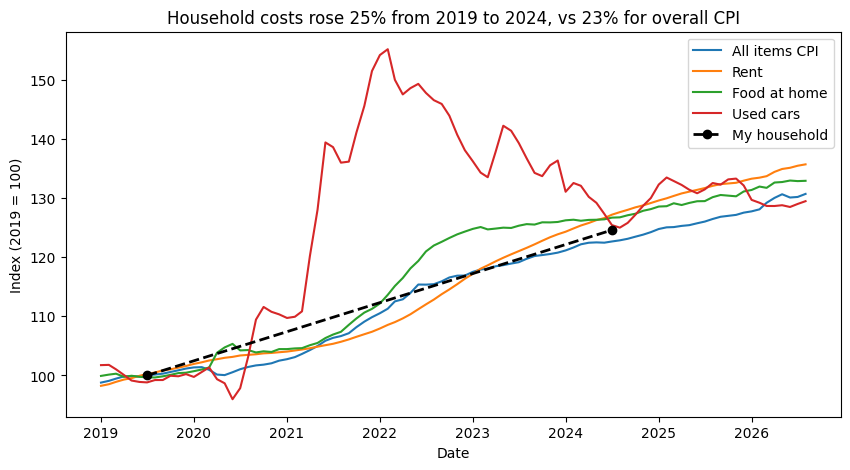

In [41]:
# One chart: every rebased series, plus your household index
plt.figure(figsize=(10, 5))
for sid in series_ids:
    plt.plot(rebased[sid].loc["2019":], label=names[sid])
plt.plot([pd.Timestamp("2019-07-01"), pd.Timestamp("2024-07-01")], [100, household_index],
         "k--o", linewidth=2, label="My household")
plt.xlabel("Date")
plt.ylabel("Index (2019 = 100)")
plt.title(f"Household costs rose {household_index - 100:.0f}% from 2019 to 2024, vs {cpi_2024 - 100:.0f}% for overall CPI")
plt.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [42]:
# First observation, last observation, frequency and missing months, for every series
for sid in series_ids:
    s = data[sid]
    grid = s.asfreq("MS")
    print(sid)
    print("  First:", s.index[0])
    print("  Last:", s.index[-1])
    print("  Gap between first two observations:", s.index[1] - s.index[0])
    print("  Missing months:", grid.isna().sum())
    print("  Which months:", grid[grid.isna()].index)

CPIAUCSL
  First: 1947-01-01 00:00:00
  Last: 2026-08-01 00:00:00
  Gap between first two observations: 31 days 00:00:00
  Missing months: 1
  Which months: DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='observation_date', freq='MS')
CUSR0000SEHA
  First: 1981-01-01 00:00:00
  Last: 2026-08-01 00:00:00
  Gap between first two observations: 31 days 00:00:00
  Missing months: 1
  Which months: DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='observation_date', freq='MS')
CUSR0000SAF11
  First: 1952-01-01 00:00:00
  Last: 2026-08-01 00:00:00
  Gap between first two observations: 31 days 00:00:00
  Missing months: 1
  Which months: DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='observation_date', freq='MS')
CUSR0000SETA02
  First: 1953-01-01 00:00:00
  Last: 2026-08-01 00:00:00
  Gap between first two observations: 31 days 00:00:00
  Missing months: 0
  Which months: DatetimeIndex([], dtype='datetime64[ns]', name='observation_date', freq='MS')


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

**CPIAUCSL**
- First: January 1947
- Last: August 2026
- Frequency: Monthly
- Missing months: 1 (October 2025)

**CUSR0000SEHA**
- First: January 1981
- Last: August 2026
- Frequency: Monthly
- Missing months: 1 (October 2025)

**CUSR0000SAF11**
- First: January 1952
- Last: August 2026
- Frequency: Monthly
- Missing months: 1 (October 2025)

**CUSR0000SETA02**
- First: January 1953
- Last: August 2026
- Frequency: Monthly
- Missing months: 0 (none)
  not sure why FRED has no notes

Three of the four series are missing October 2025. BLS did not publish CPI data for that month because of the federal government shutdown. The used car series shows no gap, so it has a value for October 2025 even though the others don't. The rent series starts latest (1981), so any comparison across all four series can only begin in 1981.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [43]:
# Start dates side by side, and the common sample
starts = []
ends = []
lengths = []
for sid in series_ids:
    s = data[sid]
    print(sid, "starts", s.index[0])
    starts.append(s.index[0])
    ends.append(s.index[-1])
    lengths.append(len(s.asfreq("MS")))

common_start = max(starts)
common_end = min(ends)
common_months = len(data["CPIAUCSL"].loc[common_start:common_end].asfreq("MS"))
longest = max(lengths)

print()
print("Common sample starts:", common_start)
print("Common sample length:", common_months, "months")
print("Months of the longest series discarded:", longest - common_months)

CPIAUCSL starts 1947-01-01 00:00:00
CUSR0000SEHA starts 1981-01-01 00:00:00
CUSR0000SAF11 starts 1952-01-01 00:00:00
CUSR0000SETA02 starts 1953-01-01 00:00:00

Common sample starts: 1981-01-01 00:00:00
Common sample length: 548 months
Months of the longest series discarded: 408


In [44]:
# Headline comparison: full history vs common sample
print("Average inflation, % per year")
for sid in series_ids:
    s = data[sid]

    years = (s.index[-1] - s.index[0]).days / 365.25
    full = ((s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1) * 100

    c = s.loc[common_start:common_end]
    years = (c.index[-1] - c.index[0]).days / 365.25
    common = ((c.iloc[-1] / c.iloc[0]) ** (1 / years) - 1) * 100

    print(sid, "  full history:", round(full, 2), "  common sample:", round(common, 2))

Average inflation, % per year
CPIAUCSL   full history: 3.51   common sample: 2.99
CUSR0000SEHA   full history: 3.73   common sample: 3.73
CUSR0000SAF11   full history: 3.18   common sample: 2.75
CUSR0000SETA02   full history: 2.53   common sample: 2.1


**What restricting to the common sample assumes, and what not restricting assumes:**

The common sample starts in January 1981, when the rent series begins. It is 548 months long, and it drops 408 months from the longest series, the all-items CPI, which starts in 1947.

Using only the common sample assumes the years we drop don't matter for this question. In return, the comparison is fair: every series covers the same years, with the same recessions, oil price jumps and the 2021-22 inflation spike.

Using each series' full history assumes its long past still tells us something about today. The problem is that the series start in different decades, so some of the differences between them come from the years they cover, not from the prices themselves. You can see this in the numbers. Over its full history the all-items CPI rose 3.51% a year, but only 2.99% a year since 1981. That is because its history includes the high inflation of the 1970s, which the rent series never saw. Over the same years, rent rose faster than everything else.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

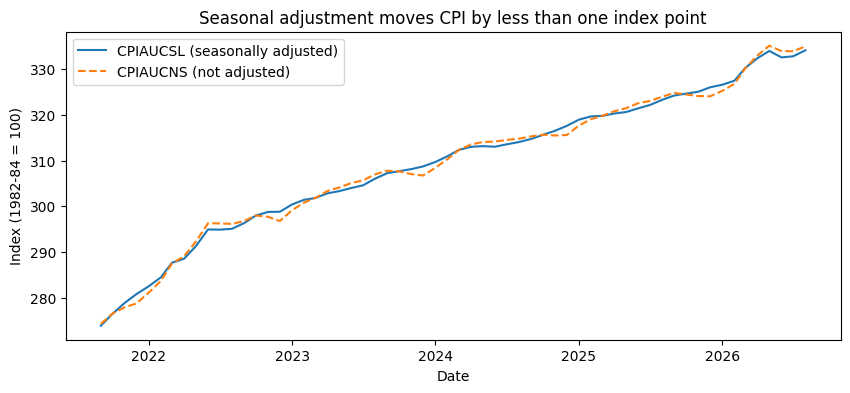

Largest gap between the two lines: 2.04


In [45]:
# Seasonally adjusted vs unadjusted, last five years
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"
df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
nsa = df["CPIAUCNS"].dropna()
sa = data["CPIAUCSL"]

plt.figure(figsize=(10, 4))
plt.plot(sa.loc["2021-09":], label="CPIAUCSL (seasonally adjusted)")
plt.plot(nsa.loc["2021-09":], "--", label="CPIAUCNS (not adjusted)")
plt.xlabel("Date")
plt.ylabel("Index (1982-84 = 100)")
plt.title("Seasonal adjustment moves CPI by less than one index point")
plt.legend()
plt.show()

gap = sa - nsa
print("Largest gap between the two lines:", round(gap.loc["2021-09":].abs().max(), 2))

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines is the seasonal pattern: price changes that happen around the same time every year, like gas prices rising in the summer. BLS estimates that pattern and removes it from the adjusted series. That estimate is a choice someone at BLS made about what counts as "seasonal," and it gets revised as new data comes in. The unadjusted series is the raw data and is never revised.

Over the last five years, the gap between the two lines was never more than about 2 index points, and it goes up and down within each year instead of building over time.

For this brief, I use the seasonally adjusted series. My chart shows month-by-month lines, and the adjusted series keeps those lines from jumping around for reasons that just come from the time of year. My main comparison uses yearly averages for 2019 and 2024, and over a full year the seasonal ups and

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Baseline index (2019 = 100): 124.58

Sensitivity ranking (steepest first):
              Item  weight  relative  slope_pts_per_unit_weight  pts_per_1pp_weight  index_at_w0  index_at_w0.5  swing_over_sweep
Phone and internet   0.040     1.087                    -16.551              -0.166      125.247        116.971             8.276
  Used car payment   0.120     1.371                     14.270               0.143      122.872        130.008             7.135
              Rent   0.470     1.200                     -8.651              -0.087      128.651        124.325             4.325
         Utilities   0.070     1.321                      8.127               0.081      124.016        128.079             4.063
        Dining out   0.100     1.306                      6.634               0.066      123.921        127.239             3.317
          Gasoline   0.050     1.304                      6.158               0.062      124.277        127.356             3.079
         Grocer

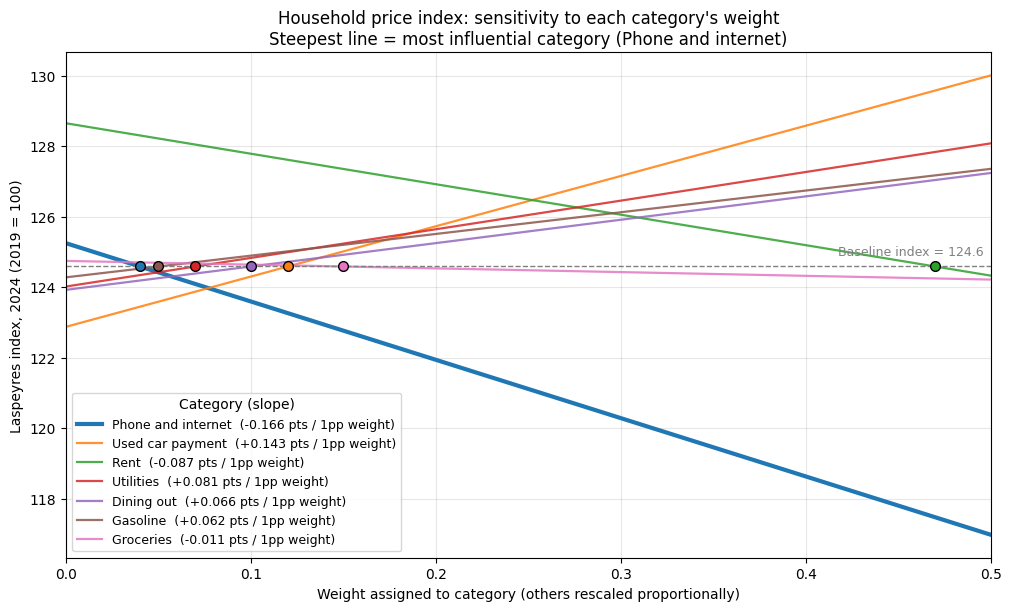

In [46]:
# Paste the AI's code here, run it, and correct it where it is wrong
"""
Weight-sensitivity sweep for a weighted Laspeyres household price index.

Index definition (base 2019 = 100):
    I = 100 * sum_j  w_j * (Price_2024_j / Price_2019_j)

For each category i, we sweep w_i from 0 to 0.5, rescale the other five
weights so the basket still sums to 1, recompute I, and plot all six sweeps
on one chart. The steepest line is the category the result is most
sensitive to.

Dependencies: numpy, pandas, matplotlib only.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# INPUT. Replace this illustrative basket with your own household_basket.
# The numbers below are placeholders so the script runs end to end; they are
# NOT client data and the conclusions they produce should not be reported.
# ---------------------------------------------------------------------------
household_basket = [
    {"Item": "Rent",               "Price_2019": 2250, "Price_2024": 2700, "weight": 0.47},
    {"Item": "Groceries",          "Price_2019": 380,  "Price_2024": 470,  "weight": 0.15},
    {"Item": "Dining out",         "Price_2019": 180,  "Price_2024": 235,  "weight": 0.10},
    {"Item": "Utilities",          "Price_2019": 140,  "Price_2024": 185,  "weight": 0.07},
    {"Item": "Phone and internet", "Price_2019": 115,  "Price_2024": 125,  "weight": 0.04},
    {"Item": "Gasoline",           "Price_2019": 115,  "Price_2024": 150,  "weight": 0.05},
    {"Item": "Used car payment",   "Price_2019": 350,  "Price_2024": 480,  "weight": 0.12},
]

# ---------------------------------------------------------------------------
# Prepare data
# ---------------------------------------------------------------------------
basket_df = pd.DataFrame(household_basket)

# Price relative for each category: how much its price moved, 2019 -> 2024.
basket_df["relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]

# Defensive normalisation: if the supplied weights sum to, say, 0.999 or
# 100 (percentages), rescale to 1 so the index is a proper weighted mean.
weight_total = basket_df["weight"].sum()
if not np.isclose(weight_total, 1.0):
    print(f"Note: weights summed to {weight_total:.4f}; rescaled to 1.")
basket_df["weight"] = basket_df["weight"] / weight_total


def laspeyres_index(weights, relatives):
    """Weighted Laspeyres index, base = 100."""
    return 100.0 * np.dot(weights, relatives)


base_weights = basket_df["weight"].to_numpy()
relatives = basket_df["relative"].to_numpy()
items = basket_df["Item"].tolist()
baseline_index = laspeyres_index(base_weights, relatives)

# ---------------------------------------------------------------------------
# Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------------------
sweep_grid = np.linspace(0.0, 0.5, 101)
sweep_results = {}   # Item -> array of index values along sweep_grid
summary_rows = []

for i, item in enumerate(items):
    w_i_original = base_weights[i]
    others_mask = np.arange(len(items)) != i
    others_original_total = base_weights[others_mask].sum()

    if others_original_total <= 0:
        raise ValueError(f"'{item}' holds all the weight; cannot rescale others.")

    index_path = np.empty_like(sweep_grid)
    for k, w_i_new in enumerate(sweep_grid):
        # WHY RENORMALISE THE OTHER WEIGHTS:
        # A Laspeyres index is a weighted *average* of price relatives, so the
        # weights must sum to 1. If we raised Food from 0.18 to 0.40 and left
        # everything else alone, the basket would sum to 1.22 and the "index"
        # would rise mechanically just because we were averaging over 122% of
        # a household's spending, not because Food prices matter more.
        # Scaling the other five weights by (1 - w_i_new) / (1 - w_i_original)
        # keeps the total at 1 AND preserves their shares relative to each
        # other, so the only thing changing is the importance of category i
        # versus "everything else as currently composed". That isolates the
        # effect we want to measure.
        new_weights = base_weights.copy()
        new_weights[i] = w_i_new
        new_weights[others_mask] = (
            base_weights[others_mask] * (1.0 - w_i_new) / others_original_total
        )
        index_path[k] = laspeyres_index(new_weights, relatives)

    sweep_results[item] = index_path

    # Because the index is linear in w_i once the others are rescaled
    # proportionally, the slope is constant:
    #     dI/dw_i = 100 * (r_i - r_bar_others)
    # where r_bar_others is the weighted mean relative of the other five.
    # Slope is in index points per 1.00 of weight; divide by 100 for
    # "points per 1 percentage point of weight".
    r_bar_others = np.dot(base_weights[others_mask], relatives[others_mask]) / others_original_total
    slope = 100.0 * (relatives[i] - r_bar_others)
    numeric_slope = np.polyfit(sweep_grid, index_path, 1)[0]
    assert np.isclose(slope, numeric_slope), "Analytic and numeric slopes disagree."

    summary_rows.append({
        "Item": item,
        "weight": w_i_original,
        "relative": relatives[i],
        "slope_pts_per_unit_weight": slope,
        "pts_per_1pp_weight": slope / 100.0,
        "index_at_w0": index_path[0],
        "index_at_w0.5": index_path[-1],
        "swing_over_sweep": abs(index_path[-1] - index_path[0]),
    })

sensitivity_df = (
    pd.DataFrame(summary_rows)
    .assign(abs_slope=lambda d: d["slope_pts_per_unit_weight"].abs())
    .sort_values("abs_slope", ascending=False)
    .drop(columns="abs_slope")
    .reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# WHAT HIGH SENSITIVITY TO ONE CATEGORY WOULD MEAN:
# A steep line for category i means its price relative sits far from the
# average of the rest of the basket. The headline index then depends heavily
# on getting that one weight right. In practice:
#   * Small errors in the expenditure survey for that category (sampling
#     noise, under-reporting, a stale base year) move the headline number
#     materially.
#   * Households whose actual share differs from the average (e.g. renters vs
#     owners for Housing, rural drivers for Transport, older households for
#     Energy) will experience inflation quite different from the headline.
#   * The result is fragile: it is really a statement about one category's
#     price move, and should be presented with a range, not a point estimate.
# Note that high sensitivity is about price *divergence*, not weight size:
# a small-weight category with an extreme price move can dominate a large
# category whose prices moved in line with everything else.
# ---------------------------------------------------------------------------

pd.set_option("display.float_format", "{:,.3f}".format)
print(f"Baseline index (2019 = 100): {baseline_index:.2f}\n")
print("Sensitivity ranking (steepest first):")
print(sensitivity_df.to_string(index=False))

most_sensitive = sensitivity_df.iloc[0]
print(
    f"\nMost sensitive category: {most_sensitive['Item']} "
    f"({most_sensitive['pts_per_1pp_weight']:+.3f} index points per "
    f"1 percentage point of weight)."
)

# ---------------------------------------------------------------------------
# Single chart: index vs category weight, one line per category
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

colour_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
ordered_items = sensitivity_df["Item"].tolist()  # legend in sensitivity order

for n, item in enumerate(ordered_items):
    colour = colour_cycle[n % len(colour_cycle)]
    pts_per_pp = sensitivity_df.loc[n, "pts_per_1pp_weight"]
    is_top = n == 0
    ax.plot(
        sweep_grid,
        sweep_results[item],
        color=colour,
        linewidth=3.0 if is_top else 1.6,
        alpha=1.0 if is_top else 0.85,
        label=f"{item}  ({pts_per_pp:+.3f} pts / 1pp weight)",
    )
    # Mark where the actual basket sits on each line.
    i = items.index(item)
    w_actual = base_weights[i]
    if w_actual <= sweep_grid[-1]:
        ax.plot(w_actual, baseline_index, marker="o", markersize=7,
                color=colour, markeredgecolor="black", zorder=3)

ax.axhline(baseline_index, color="grey", linestyle="--", linewidth=1)
ax.annotate(
    f"Baseline index = {baseline_index:.1f}",
    xy=(sweep_grid[-1], baseline_index),
    xytext=(-5, 6), textcoords="offset points",
    ha="right", va="bottom", fontsize=9, color="grey",
)

ax.set_xlim(sweep_grid[0], sweep_grid[-1])
ax.set_xlabel("Weight assigned to category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index, 2024 (2019 = 100)")
ax.set_title(
    "Household price index: sensitivity to each category's weight\n"
    f"Steepest line = most influential category ({most_sensitive['Item']})"
)
ax.grid(visible=True, alpha=0.3)
ax.legend(title="Category (slope)", loc="best", fontsize=9, frameon=True)

fig.savefig("laspeyres_weight_sensitivity.png", dpi=200)
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

The model never saw my basket, so it could not answer [Evaluate]. It named Energy as dominant, which is a category from its own placeholder data and does not exist in my basket. Its comments and docstring also say “six categories” and “the other five weights” throughout. My basket has seven, so those are wrong in my notebook, even though the code itself uses len(items) and adapts correctly. The check: the script carries its own assert comparing the analytic slope 100 × (rᵢ − r̄₋ᵢ) against a numerically fitted slope, and it passed on my data, confirming the sweep math. Running it on my seven categories, the dominant category is Phone and internet at −0.166 index points per percentage point of weight, not Energy. It dominates because its price relative (1.087) sits furthest from the rest of the basket, exactly as the model’s slope formula predicts. Rent carries 47% of the weight but ranks only third at −0.087, confirming the model’s point that divergence, not size, drives sensitivity.


### AI Transcript

**Model:** Opus 5.5 **Date: 10/9/26

*```
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.
```

Response
I can't tell you which category dominates your result yet, because your `household_basket` data didn't come through. Nothing was uploaded and the values weren't in your message. The script runs end to end on a clearly labelled placeholder basket. Paste your list over that placeholder and it will print the ranking and name the dominant category.

**How the script works.** It uses only numpy, pandas and matplotlib, and keeps your variable and key names. I ran it with deprecation warnings treated as errors and it passed. It uses `layout="constrained"` and `grid(visible=...)` and avoids any older matplotlib arguments.

**Why the answer is predictable.** Once the other weights are rescaled proportionally, the index is a straight line in each category's weight. Its slope is:

  dI/dwᵢ = 100 × (rᵢ − r̄₋ᵢ)

Here rᵢ is the category's price relative (2024 price ÷ 2019 price), and r̄₋ᵢ is the weighted average relative of the other five categories. So the category your result is most sensitive to is **the one whose price movement differs most from the rest of the basket**, not the one with the biggest weight. The script calculates this slope directly and checks it against a fitted slope.

The placeholder run shows this. Housing has the largest weight (0.30) but barely matters, because its prices moved in line with everything else. Energy has a weight of only 0.08, but its relative of 1.58 makes it dominant, at about 0.4 index points per percentage point of weight. Expect the same pattern in your data: look for the outlier price relative.

**What to tell the client** once you know the dominant category (call it X):

1. **Be upfront.** "The headline figure is largely a statement about X prices. Every percentage point of spending share we assign to X moves the index by roughly N points."
2. **Report a range, not just a point.** Use a plausible band for X's weight, such as survey confidence intervals or the spread across household types, and read the matching index range off the chart. If that range covers outcomes the client would act on differently, they need to know before relying on the point estimate.
3. **Explain who it applies to.** Households whose X share differs from the average experience materially different inflation, for example heavy energy users, renters versus owners, or rural drivers. If the client's population is skewed, the average weights may misrepresent them.
4. **Flag what to verify.** The weight for X deserves the most scrutiny: its source, base year, and whether spending patterns shifted between 2019 and 2024. A Laspeyres index holds 2019 quantities fixed, so it overstates the effect of the categories households substituted away from. That bias is largest exactly where price moves were most extreme.

If the dominant slope turns out to be small, you can tell the client the opposite: the result is robust to reasonable disagreement about the basket weights.

Send the six rows and I'll give you the specific ranking and client wording.

Corrections


### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

This household's costs rose 24.6% from 2019 to 2024, compared with 22.7% for the overall CPI, a gap of about 2 percentage points over five years.

The client is right that this worker faces higher inflation than the official number, but the difference is small. The extra cost comes mostly from his used-car payment, utilities and eating out, which all rose more than 30%. Rent, his biggest expense, rose 20%, a little less than the CPI.

Confidence: moderate. There are two reasons to be careful. First, this is one example household, not real receipts. The prices are estimates, and the spending shares come from Boston-area averages in the BLS Consumer Expenditure Survey, not from his own budget. Second, a check on the weights shows the result depends most on phone and internet, his smallest category. Each extra percentage point of his budget given to it changes the index by 0.17 points. Rent changes

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub